# When should the mixer stop?
**Batch blending energy optimization · Independent simulated case study**

A 500 L batch of water receives a small dose of soluble dye. Two virtual probes track the local concentration. Choose a mixer speed and a fixed run time that bring both probes within 5% of target before a deadline, using the least modeled shaft energy among tested speeds. This study keeps tank geometry fixed.

**Run it:** Run all cells in order. Change only the deadline in the first cell for your first experiment. Tables and figures are written to the output folder. Every probe reading is synthetic. The generation code makes the assumptions reproducible.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

deadline_s = 90   # try 75, 110, or 20 seconds
if not np.isfinite(deadline_s) or deadline_s <= 0:
    raise ValueError("Enter a positive, finite deadline in seconds.")
out = Path("output")
out.mkdir(exist_ok=True)
speeds = [90, 120, 150, 180, 210, 240]
rho = 1000.0         # kg/m³
mu = 0.001           # Pa·s
diameter = 0.35      # m
power_number = 1.3   # illustrative constant turbulent power number
baseline_rpm = 240   # assumed reference operating policy

## 1 · Generate the two probe signals
The final target concentration is normalized to 1.0. The far probe initially sees almost no dye, while a near probe sees a concentrated plume. Both approach 1.0. The simulated decay time varies inversely with speed, with a bounded random multiplier for each run. Add small independent sensor noise. These two local signals are phenomenological examples, not a tank-wide concentration field. Four runs per speed give a small sample of variability.

In [2]:
rng = np.random.default_rng(42)
seconds = np.arange(0, 211, 1)
frames = []
for rpm in speeds:
    for run in range(1, 5):
        variability = rng.uniform(0.90, 1.10)
        tau = 26 * (150 / rpm) * variability
        for probe, amplitude, tau_factor in [("Near", 0.70, 0.72), ("Far", -1.0, 1.0)]:
            signal = 1 + amplitude * np.exp(-seconds / (tau * tau_factor))
            signal += rng.normal(0, 0.004, len(seconds))
            frames.append(pd.DataFrame({"rpm": rpm, "run": run, "probe": probe,
                                        "seconds": seconds, "normalized_signal": signal}))
raw = pd.concat(frames, ignore_index=True)
raw.to_csv(out / "synthetic_tracer.csv", index=False)
print(f"{len(raw):,} synthetic readings; {len(speeds)} speeds × 4 runs × 2 probes.")

10,128 synthetic readings; 6 speeds × 4 runs × 2 probes.


## 2 · Detect a sustained endpoint
For each run, find the first sampled second after the final excursion by either probe outside [0.95, 1.05]. Require at least 10 more seconds of recorded data after that point. This is a retrospective endpoint measured from a full trace. A transient crossing is insufficient. If an endpoint is unconfirmed in any run, exclude that speed. The fixed mixing time for a speed is the slowest confirmed endpoint across its four runs.

In [3]:
def blend_endpoint(frame):
    probes = frame.pivot(index="seconds", columns="probe", values="normalized_signal").sort_index()
    if set(probes.columns) != {"Near", "Far"} or probes.isna().any().any():
        raise ValueError("Both probes must have a reading at every sampled time.")
    time = probes.index.to_numpy()
    if len(time) == 0 or time[0] != 0 or not np.all(np.diff(time) == 1):
        raise ValueError("Expected a complete one-second sampling grid starting at zero.")
    in_band = ((probes >= 0.95) & (probes <= 1.05)).all(axis=1)
    excursions = np.flatnonzero(~in_band)
    first = excursions[-1] + 1 if len(excursions) else 0
    if first >= len(time) or time[-1] - time[first] < 10:
        return np.nan
    return float(time[first])

records = []
for (rpm, run), series in raw.groupby(["rpm", "run"]):
    records.append({"rpm": rpm, "run": run, "blend_s": blend_endpoint(series)})
runs = pd.DataFrame(records)
runs.to_csv(out / "run_endpoints.csv", index=False)

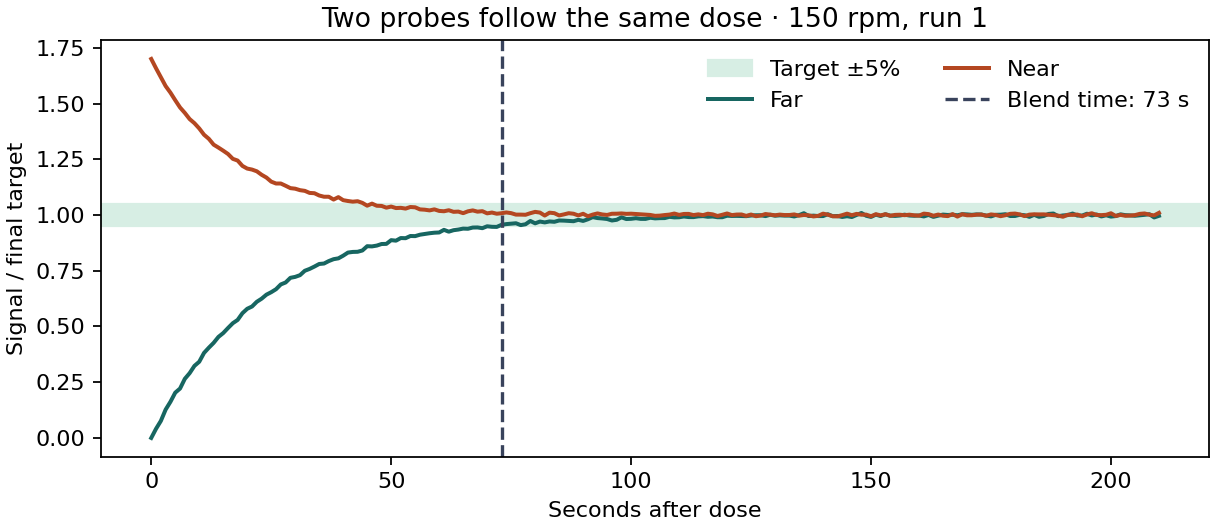

In [4]:
example = raw[(raw.rpm == 150) & (raw.run == 1)]
endpoint = blend_endpoint(example)
fig, ax = plt.subplots(figsize=(7.6, 3.3), constrained_layout=True)
ax.axhspan(0.95, 1.05, color="#d7eee4", label="Target ±5%")
for (probe, series), color in zip(example.groupby("probe"), ["#176661", "#b44721"]):
    ax.plot(series.seconds, series.normalized_signal, label=probe, color=color, lw=1.8)
ax.axvline(endpoint, color="#39435c", ls="--", label=f"Blend time: {endpoint:.0f} s")
ax.set(xlabel="Seconds after dose", ylabel="Signal / final target", title="Two probes follow the same dose · 150 rpm, run 1")
ax.legend(frameon=False, ncol=2)
fig.savefig(out / "tracer_example.png", dpi=160)
plt.show()

## 3 · Price each speed in energy
For a baffled tank with one impeller, use $P=N_p\rho N^3D^5$, with $N=\mathrm{rpm}/60$ and $P$ in watts. The impeller Reynolds number is $Re=\rho ND^2/\mu$. All tested speeds fall above 180,000 in this water-like case. Assume a constant power number of 1.3 for this idealized calculation. Convert shaft power and the scheduled mixing time to energy: $E_{\mathrm{Wh}}=P\,t/3600$. Electricity metered at the wall would also include motor and drive losses.

Select the lowest energy among speeds whose scheduled time meets the deadline. The 240 rpm reference uses its own scheduled time, so both policies receive credit for stopping when the batch is blended.

In [5]:
summary = runs.groupby("rpm").blend_s.agg(["count", "median", "max"]).reset_index()
summary.columns = ["rpm", "confirmed_runs", "median_s", "scheduled_s"]
summary.loc[summary.confirmed_runs != 4, "scheduled_s"] = np.nan
speed_hz = summary.rpm / 60
summary["Re"] = rho * speed_hz * diameter**2 / mu
summary["shaft_W"] = power_number * rho * speed_hz**3 * diameter**5
summary["batch_Wh"] = summary.shaft_W * summary.scheduled_s / 3600

def choose(limit):
    feasible = summary[summary.scheduled_s <= limit]
    if feasible.empty:
        return None
    return feasible.sort_values(["batch_Wh", "scheduled_s"]).iloc[0]

best = choose(deadline_s)
summary["meets_deadline"] = summary.scheduled_s <= deadline_s
summary.to_csv(out / "speed_comparison.csv", index=False)
print(summary.round(2).to_string(index=False))
reference = summary[summary.rpm == baseline_rpm].iloc[0]
if best is None:
    print("No tested speed meets this deadline.")
else:
    savings = 100 * (1 - best.batch_Wh / reference.batch_Wh)
    print(f"Selected {best.rpm:.0f} rpm for {best.scheduled_s:.0f} s: "
          f"{best.batch_Wh:.2f} Wh, {savings:.1f}% less shaft energy than the reference.")

 rpm  confirmed_runs  median_s  scheduled_s       Re  shaft_W  batch_Wh  meets_deadline
  90               4     135.5        137.0 183750.0    23.04      0.88           False
 120               4      97.5        107.0 245000.0    54.62      1.62           False
 150               4      75.0         80.0 306250.0   106.69      2.37            True
 180               4      68.5         72.0 367500.0   184.35      3.69            True
 210               4      59.0         61.0 428750.0   292.74      4.96            True
 240               4      48.5         51.0 490000.0   436.98      6.19            True
Selected 150 rpm for 80 s: 2.37 Wh, 61.7% less shaft energy than the reference.


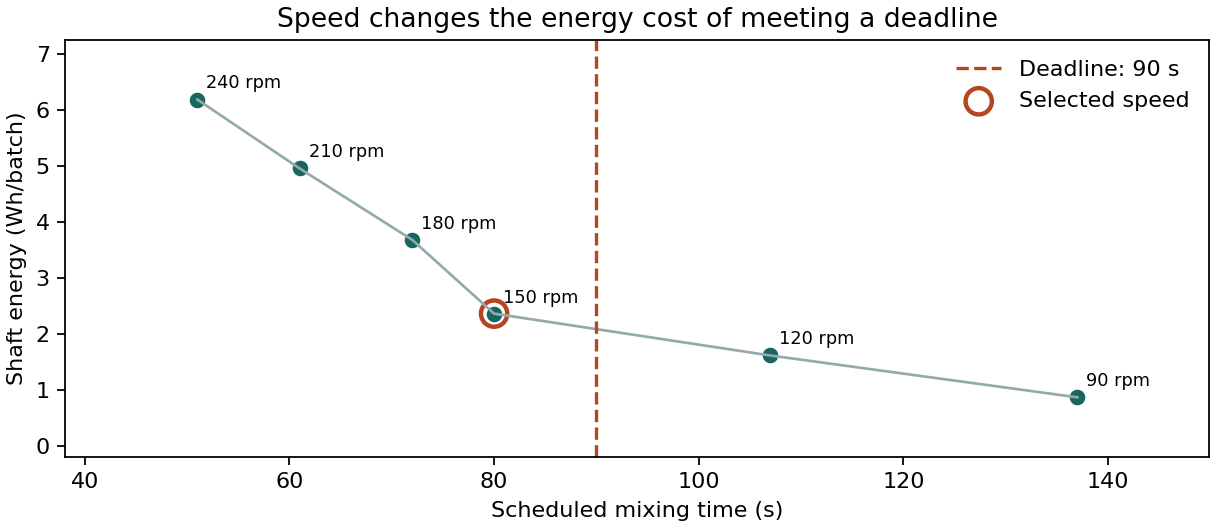

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 3.3), constrained_layout=True)
ax.plot(summary.scheduled_s, summary.batch_Wh, color="#94aaa9", lw=1.2)
ax.scatter(summary.scheduled_s, summary.batch_Wh, color="#176661", s=36)
for row in summary.itertuples():
    ax.annotate(f"{row.rpm} rpm", (row.scheduled_s, row.batch_Wh),
                xytext=(4, 5), textcoords="offset points", fontsize=8)
ax.axvline(deadline_s, ls="--", color="#b44721", label=f"Deadline: {deadline_s} s")
if best is not None:
    ax.scatter(best.scheduled_s, best.batch_Wh, s=140, facecolors="none",
               edgecolors="#b44721", lw=2, label="Selected speed")
ax.set(xlabel="Scheduled mixing time (s)", ylabel="Shaft energy (Wh/batch)",
       title="Speed changes the energy cost of meeting a deadline")
ax.margins(x=0.15, y=0.2)
ax.legend(frameon=False)
fig.savefig(out / "energy_tradeoff.png", dpi=160)
plt.show()

## 4 · Test the decision
Tighten or relax the deadline. A shorter deadline may force a higher speed or eliminate every tested speed. Checks below cover false early crossings, an unconfirmed trace, a hand calculation of power at 120 rpm, and the absence of feasible speeds for a 1-second limit.

In [7]:
cases = []
for limit in sorted({20, 75, 90, 110, 160, deadline_s}):
    pick = choose(limit)
    cases.append({"deadline_s": limit, "selected_rpm": None if pick is None else pick.rpm,
                  "scheduled_s": None if pick is None else pick.scheduled_s,
                  "batch_Wh": None if pick is None else pick.batch_Wh})
policies = pd.DataFrame(cases)
policies.to_csv(out / "deadline_sensitivity.csv", index=False)
print(policies.round(2).fillna("infeasible").to_string(index=False))

test = pd.DataFrame({"seconds": np.tile(np.arange(21), 2), "probe": np.repeat(["Near", "Far"], 21),
                     "normalized_signal": np.ones(42)})
test.loc[(test.probe == "Far") & (test.seconds == 7), "normalized_signal"] = 0.8
assert blend_endpoint(test) == 8
test.loc[test.seconds == 18, "normalized_signal"] = 1.2
assert np.isnan(blend_endpoint(test))
assert np.isclose(summary.loc[summary.rpm == 120, "shaft_W"].iloc[0], 54.62275)
assert choose(1) is None
if best is not None:
    assert best.scheduled_s <= deadline_s
    assert np.isclose(best.batch_Wh, summary.loc[summary.meets_deadline, "batch_Wh"].min())
print("PASS: endpoint detection, incomplete settling, power units and constrained selection.")

 deadline_s selected_rpm scheduled_s   batch_Wh
         20   infeasible  infeasible infeasible
         75        180.0        72.0       3.69
         90        150.0        80.0       2.37
        110        120.0       107.0       1.62
        160         90.0       137.0       0.88
PASS: endpoint detection, incomplete settling, power units and constrained selection.


## Interpretation and sources
The slowest confirmed run gives a scheduling allowance for the four simulated trials at each speed. It is not a statistical guarantee for future batches. Because the generator assumes faster mixing at higher rpm while shaft power rises cubically, this simulation favors slower feasible speeds. Testing a real tank would require representative probe locations, repeated tracer trials and measured power.

**Engineering background:** [André Bakker, Lectures on Modeling Reacting Flows in Stirred Tanks](https://www.bakker.org/Lectures-Reacting-Flows.pdf) discusses tracer settling within a target band. [University of Michigan, Mixing in Chemical Reactors](https://websites.umich.edu/~elements/01chap/html/reactors/mixing/dn.htm) introduces impeller Reynolds and power numbers. The simulation constants and signals were chosen for this study.